# 05 · ¿Con qué calor se camina a Magdalena?

Las recomendaciones oficiales a los peregrinos insisten en agua, suero y sombrero. Este notebook mide el calor real durante las fiestas (26 de septiembre al 6 de octubre) desde 1995, en tres puntos de la ruta: Nogales (salida), Ímuris (primera escala) y Magdalena (llegada).

**Fuente:** reanálisis ERA5 vía la API histórica de Open-Meteo. Es una malla de ~25 km, no una estación meteorológica: sirve para comparar años entre sí, no para afirmar la temperatura exacta de un punto de la carretera.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema
from src import procesamiento as proc

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
clima = pd.concat([proc.leer_clima(p) for p in ["nogales", "imuris", "magdalena"]], ignore_index=True)
fiestas = clima[proc.en_ventana_fiestas(clima["fecha"])].copy()
fiestas["anio"] = fiestas["fecha"].dt.year
print(f"Días en ventana de fiestas: {fiestas.groupby('punto').size().to_dict()}  ·  último año completo: {fiestas['anio'].max()}")

Días en ventana de fiestas: {'imuris': 341, 'magdalena': 341, 'nogales': 341}  ·  último año completo: 2025


In [3]:
resumen = (
    fiestas.groupby(["punto", "anio"])
    .agg(t_max_promedio=("t_max", "mean"), t_max_pico=("t_max", "max"),
         dias_35_o_mas=("t_max", lambda s: int((s >= 35).sum())), t_min_promedio=("t_min", "mean"),
         lluvia_mm=("precipitacion_mm", "sum"), dias=("t_max", "size"))
    .round(1)
    .reset_index()
)
magdalena = resumen[resumen["punto"] == "magdalena"].set_index("anio")
magdalena.sort_values("t_max_promedio", ascending=False).head(8)

,punto,t_max_promedio,t_max_pico,dias_35_o_mas,t_min_promedio,lluvia_mm,dias
anio,,,,,,,
2024,magdalena,39.4,41.9,11,21.4,0.0,11
2020,magdalena,37.4,38.5,11,20.7,0.0,11
1999,magdalena,35.2,36.9,5,18.6,0.0,11
2005,magdalena,35.0,38.7,6,20.8,0.7,11
2000,magdalena,34.6,36.7,3,20.3,0.4,11
2023,magdalena,34.4,38.9,6,18.3,0.0,11
1997,magdalena,34.2,36.4,4,19.5,0.0,11
2012,magdalena,33.6,36.3,4,18.8,0.3,11


## 1. 2024: las fiestas más calurosas en tres décadas

In [4]:
base = magdalena.loc[1995:2023, "t_max_promedio"]
anomalia_2024 = magdalena.loc[2024, "t_max_promedio"] - base.mean()
print(f"Promedio de máximas en fiestas, 1995-2023: {base.mean():.1f} °C (desv. est. {base.std():.1f})")
print(f"2024: {magdalena.loc[2024, 't_max_promedio']} °C promedio, pico de {magdalena.loc[2024, 't_max_pico']} °C, "
      f"{magdalena.loc[2024, 'dias_35_o_mas']} de {magdalena.loc[2024, 'dias']} días con 35 °C o más")
print(f"Anomalía 2024: +{anomalia_2024:.1f} °C, {anomalia_2024 / base.std():.1f} desviaciones estándar sobre el promedio")

Promedio de máximas en fiestas, 1995-2023: 32.2 °C (desv. est. 2.1)
2024: 39.4 °C promedio, pico de 41.9 °C, 11 de 11 días con 35 °C o más
Anomalía 2024: +7.2 °C, 3.4 desviaciones estándar sobre el promedio


In [5]:
pd.pivot_table(resumen[resumen["anio"].isin([2020, 2023, 2024, 2025])], index="anio", columns="punto", values="t_max_promedio")

punto,imuris,magdalena,nogales
anio,,,
2020,37.0,37.4,33.8
2023,34.6,34.4,31.7
2024,39.3,39.4,36.1
2025,29.6,29.7,28.2


El patrón se repite en los tres puntos de la ruta: 2024 es el máximo de la serie incluso en Nogales, que por altitud es el tramo más fresco. Curiosamente 2020, el año en que la fiesta se suspendió, fue el segundo más caluroso.

## 2. Figura

Interactiva: outputs/figuras/06_calor_fiestas.html


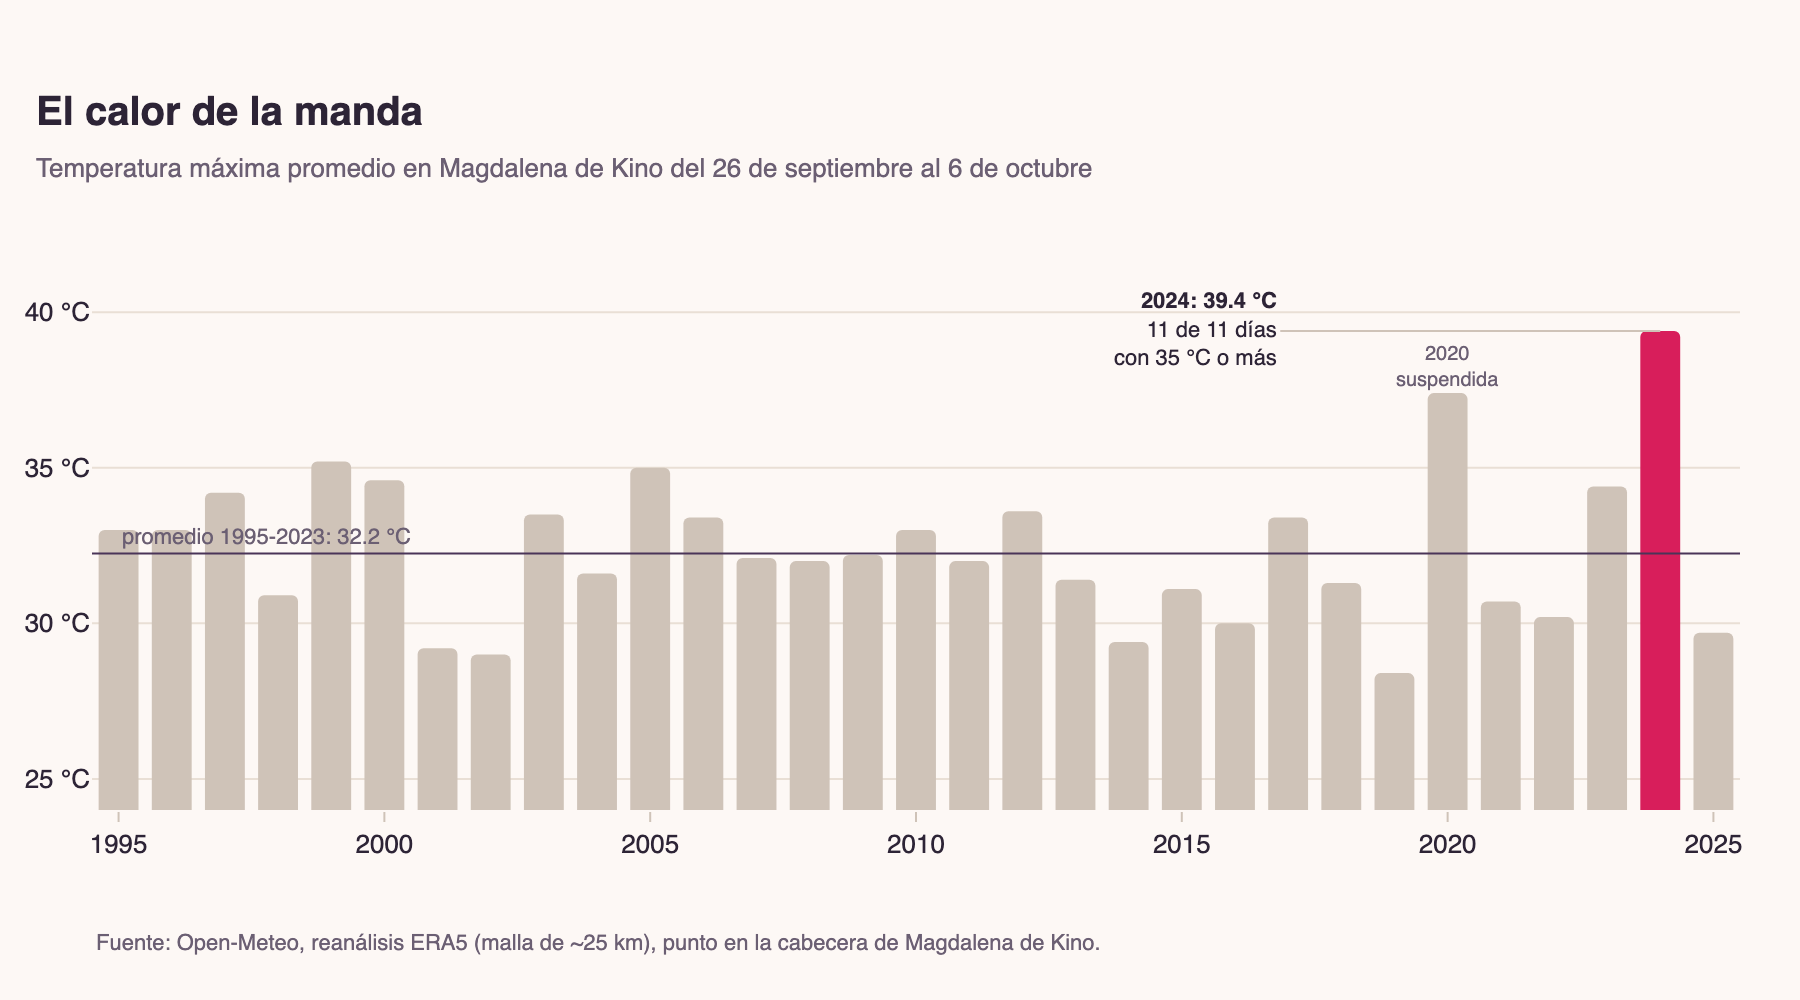

In [6]:
serie = magdalena.reset_index()
color = [tema.PROTAGONISTA if a == 2024 else tema.NEUTRO for a in serie["anio"]]
fig = go.Figure(go.Bar(
    x=serie["anio"], y=serie["t_max_promedio"], marker=dict(color=color, line=dict(width=0), cornerradius=3),
    customdata=serie[["t_max_pico", "dias_35_o_mas"]],
    hovertemplate="<b>%{x}</b><br>Máxima promedio: %{y:.1f} °C<br>Pico: %{customdata[0]:.1f} °C"
                  "<br>Días con 35 °C o más: %{customdata[1]}<extra></extra>",
))
fig.add_hline(y=base.mean(), line=dict(color=tema.CONTORNO, width=1))
fig.add_annotation(x=1995, y=base.mean(), text=f"promedio 1995-2023: {base.mean():.1f} °C", xanchor="left",
                   yanchor="bottom", showarrow=False, font=dict(size=11, color=tema.TEXTO_SUAVE))
fig.add_annotation(x=2024, y=magdalena.loc[2024, "t_max_promedio"],
                   text=f"<b>2024: {magdalena.loc[2024, 't_max_promedio']:.1f} °C</b><br>11 de 11 días<br>con 35 °C o más",
                   xanchor="right", yanchor="middle", ax=-190, ay=0, showarrow=True, arrowcolor=tema.NEUTRO,
                   font=dict(size=11, color=tema.TEXTO), align="right")
fig.add_annotation(x=2020, y=magdalena.loc[2020, "t_max_promedio"], text="2020<br>suspendida", yanchor="bottom",
                   showarrow=False, font=dict(size=10, color=tema.TEXTO_SUAVE))
fig.update_layout(
    title=tema.titulo("El calor de la manda", "Temperatura máxima promedio en Magdalena de Kino del 26 de septiembre al 6 de octubre"),
    yaxis=dict(range=[24, 42], ticksuffix=" °C", title=None),
    xaxis=dict(dtick=5, title=None), bargap=0.25, height=500, showlegend=False,
)
tema.nota_fuente(fig, "Fuente: Open-Meteo, reanálisis ERA5 (malla de ~25 km), punto en la cabecera de Magdalena de Kino.")
tema.mostrar(fig, "06_calor_fiestas")

**Lectura:** el año en que el municipio proyectó la mayor afluencia (150 mil) fue también el más caluroso de la serie. No tenemos cifras de atenciones por golpe de calor para cruzarlo; es un hueco que vale la pena pedir por transparencia a Protección Civil y Cruz Roja.

## Conclusiones

- La máxima promedio de las fiestas ronda los 32 °C en Magdalena.
- **2024 fue el año más caluroso desde al menos 1995**: 39.4 °C de promedio, pico de 41.9 °C y los 11 días arriba de 35 °C.
- 2025 volvió a la normalidad (29.7 °C).

In [7]:
resumen.to_csv(config.DIR_PROCESSED / "clima_ventana_fiestas.csv", index=False)